In [1]:
# # Run this and then restart the kernel at the start of each session to install
# # 'teotil3' in development mode
# !pip install -e /home/jovyan/projects/teotil3/

In [2]:
import sys
import warnings

sys.path.append("/home/jovyan/projects/mjosa_water_temp/code")
sys.path.append("/home/jovyan/development/nivapy3/nivapy3")

import os

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import nivapy3 as nivapy
import pandas as pd
import requests
import stats
import teotil3 as teo
import utils
from xyzservices import TileProvider

warnings.simplefilter("ignore")
plt.style.use("ggplot")

In [3]:
# Connect to JupyterHub's PostGIS database
eng = nivapy.da.connect_postgis()

# Define provider for Kartverket basemaps
kartverket = TileProvider(
    name="Kartverket",
    url="https://cache.kartverket.no/v1/wmts/1.0.0/topo/default/webmercator/{z}/{y}/{x}.png",
    attribution="© Kartverket",
)

Connection successful.


# TOTN fluxes for Åros

A quick sense-check of fluxes simulated by TEOTIL3 for Åroselva.

In [4]:
# Area of interest
stn_list = [
    "009-61619"
]  # Downstream-most station in Åroselva, about 500 m from outflow to Oslofjord
reg_id = "009.A0"  # Downstream-most regine for Åroselva

# Vannmiljø query params
par_list = ["N-TOT"]
st_yr, end_yr = 2020, 2025

# Bias correction for NVE flow simulations.
# Set to 1 for no correction
gts_bias_fac = 1

# TEOTIL3 params
teo3_st_yr = 2013
teo3_end_yr = 2024
nve_data_year = 2025
admin_year = 2024
agri_loss = "annual"

## 1. Get data from Vannmiljø

In [5]:
# Query Vannmiljø
data = {
    "FromRegDate": f"{st_yr}-01-01",
    "WaterLocationCodeFilter": stn_list,
}
wc_df = nivapy.da.post_data_to_vannmiljo("GetRegistrations", data=data)

# Tidy to cols of interest
names_dict = {
    "WaterLocationID": "station_id",
    "WaterLocationCode": "station_code",
    "Name": "station_name",
    "WaterCategory": "category",
    "CoordX": "utm33_east",
    "CoordY": "utm33_north",
    "FylkeID": "fylke_id",
    "Fylke": "fylke_name",
    "KommuneID": "kommune_id",
    "Kommune": "kommune_name",
    "VassdragsomradeID": "vassom_id",
    "Vassdragsomrade": "vassom_name",
    "VannomradeID": "vannom_id",
    "Vannomrade": "vannom_name",
    "VannregionID": "vannreg_id",
    "Vannregion": "vannreg_name",
    "WaterBodyID": "waterbody_id",
    "WaterBody": "waterbody_name",
    "FeatureType": "feature_type",
    "ActivityID": "activity_id",
    "ActivityName": "activity_name",
    "Employer": "employer",
    "Contractor": "contractor",
    "MediumName": "medium_name",
    "SamplingTime": "sample_date",
    "UpperDepth": "upper_depth",
    "LowerDepth": "lower_depth",
    "FilteredSample": "filtered",
    "ParameterID": "par_id",
    "ParameterName": "par_name",
    "ValueOperator": "flag",
    "RegValue": "value",
    "Unit": "unit",
    "DetectionLimit": "lod",
    "QuantificationLimit": "loq",
}
stn_cols = [
    "station_id",
    "station_code",
    "station_name",
    "feature_type",
    "category",
    "fylke_id",
    "fylke_name",
    "kommune_id",
    "kommune_name",
    "vassom_id",
    "vassom_name",
    "vannom_id",
    "vannom_name",
    "vannreg_id",
    "vannreg_name",
    "waterbody_id",
    "waterbody_name",
    "utm33_east",
    "utm33_north",
]
wc_df = wc_df[names_dict.keys()].rename(columns=names_dict)
wc_df = wc_df.query("medium_name == 'Ferskvann'")
wc_df = wc_df.query("par_id in @par_list")
wc_df["sample_date"] = pd.to_datetime(wc_df["sample_date"])
stn_df = wc_df[stn_cols].drop_duplicates(subset="station_code").reset_index(drop=True)
stn_gdf = gpd.GeoDataFrame(
    stn_df,
    geometry=gpd.points_from_xy(
        stn_df["utm33_east"], stn_df["utm33_north"], crs="epsg:25833"
    ),
)

# Prepare to convert to wide
wc_df["filtered"] = wc_df["filtered"].map({True: "Filt", False: "Ufilt"})
wc_df["par_unit"] = (
    wc_df["par_id"] + "_" + wc_df["filtered"].astype(str) + "_" + wc_df["unit"]
)
wc_df = wc_df.drop(
    columns=["par_id", "par_name", "flag", "unit", "filtered", "lod", "loq"]
)
wc_df["upper_depth"] = wc_df["upper_depth"].fillna(0)
wc_df["lower_depth"] = wc_df["lower_depth"].fillna(0)
wc_df = wc_df.dropna(subset="value").fillna("none")
id_cols = [col for col in wc_df.columns if col != "value"]

# Save duplicated values for checking
dup_df = wc_df[wc_df.duplicated(subset=id_cols, keep=False)].sort_values(id_cols)
if len(dup_df) > 0:
    print(
        "The dataset contains duplicates. These will be saved for checking and then averaged."
    )
    dup_xlsx = r"vm_duplicates.xlsx"
    dup_df.to_excel(dup_xlsx, index=False)

    # Average duplicates
    wc_df = wc_df.groupby(id_cols).mean().reset_index()

# Convert to wide
wc_df = wc_df.set_index(id_cols).unstack("par_unit")
wc_df.columns = wc_df.columns.get_level_values(1)
wc_df = wc_df.reset_index()

# Tidy
wc_df = wc_df.rename(columns={"N-TOT_Ufilt_µg/l N": "TOTN_ug/l"})
cols = [
    "station_code",
    "station_name",
    "sample_date",
    "upper_depth",
    "lower_depth",
    "TOTN_ug/l",
]
wc_df = wc_df[cols]

print("Station details:")
display(stn_df)

print("Water chemistry:")
display(wc_df)

Station details:


,station_id,station_code,station_name,feature_type,category,fylke_id,fylke_name,kommune_id,kommune_name,vassom_id,vassom_name,vannom_id,vannom_name,vannreg_id,vannreg_name,waterbody_id,waterbody_name,utm33_east,utm33_north
0,61619,009-61619,"Åroselva v/Astrid Skares vei, ÅRO H",point,R,32,Akershus,3203,Asker,009,Årosvassdraget/indre Oslofjorden vest,5110-11,Indre Oslofjord Vest,5110,Glomma,009-183-R,Åroselva,247585.7,6627344.2


Water chemistry:


par_unit,station_code,station_name,sample_date,upper_depth,lower_depth,TOTN_ug/l
0,009-61619,"Åroselva v/Astrid Skares vei, ÅRO H",2020-01-30,0.0,0.0,2200.0
1,009-61619,"Åroselva v/Astrid Skares vei, ÅRO H",2020-02-27,0.0,0.0,1600.0
2,009-61619,"Åroselva v/Astrid Skares vei, ÅRO H",2020-03-26,0.0,0.0,1300.0
3,009-61619,"Åroselva v/Astrid Skares vei, ÅRO H",2020-04-30,0.0,0.0,1800.0
4,009-61619,"Åroselva v/Astrid Skares vei, ÅRO H",2020-05-28,0.0,0.0,1100.0
...,...,...,...,...,...,...
64,009-61619,"Åroselva v/Astrid Skares vei, ÅRO H",2024-11-21,0.0,0.0,1100.0
65,009-61619,"Åroselva v/Astrid Skares vei, ÅRO H",2024-12-19,0.0,0.0,2000.0
66,009-61619,"Åroselva v/Astrid Skares vei, ÅRO H",2018-07-05,0.0,0.0,1600.0
67,009-61619,"Åroselva v/Astrid Skares vei, ÅRO H",2019-07-04,0.0,0.0,1400.0


## 2. Derive catchment boundary

For the water chemistry station.

In [6]:
cat_gdf = nivapy.spatial.derive_watershed_boundaries(
    stn_df,
    id_col="station_code",
    xcol="utm33_east",
    ycol="utm33_north",
    crs="epsg:25833",
    min_size_km2=10,
    dem_res_m=40,
    buffer_km=None,
    temp_fold=None,
    reproject=False,
)
cat_gdf["cat_area_km2"] = cat_gdf.to_crs({"proj": "cea"}).geometry.area / 1e6

cat_gdf

Connection successful.


Looping over vassdragsområder:   0%|          | 0/1 [00:00<?, ?it/s]

Looping over outlets in vassdragsområder 009:   0%|          | 0/1 [00:00<?, ?it/s]

,station_code,geometry,station_id,station_name,feature_type,category,fylke_id,fylke_name,kommune_id,kommune_name,...,vassom_name,vannom_id,vannom_name,vannreg_id,vannreg_name,waterbody_id,waterbody_name,utm33_east,utm33_north,cat_area_km2
0,009-61619,"POLYGON ((236960 6645080, 236960 6645000, 2369...",61619,"Åroselva v/Astrid Skares vei, ÅRO H",point,R,32,Akershus,3203,Asker,...,Årosvassdraget/indre Oslofjorden vest,5110-11,Indre Oslofjord Vest,5110,Glomma,009-183-R,Åroselva,247585.7,6627344.2,113.912403


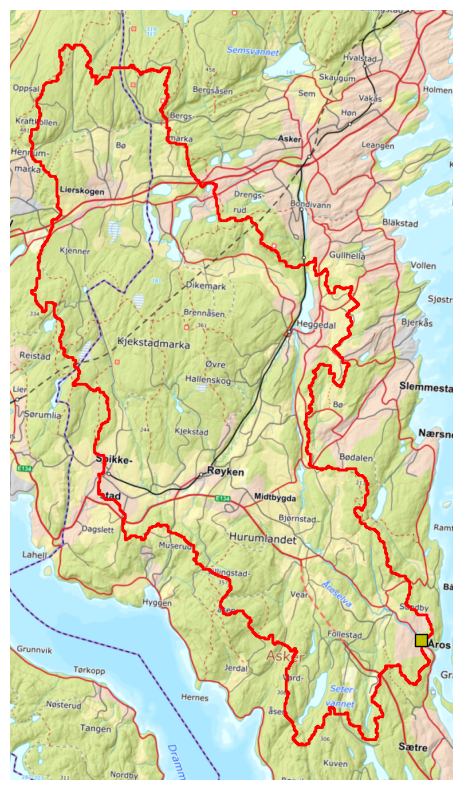

In [7]:
# Plot
ax = cat_gdf.plot(figsize=(10, 10), edgecolor="r", facecolor="none", lw=2)
stn_gdf.plot(ax=ax, marker="s", edgecolor="k", facecolor="y", lw=1, markersize=75)
cx.add_basemap(ax, crs=cat_gdf.crs, source=kartverket, attribution=False)
ax.set_axis_off()

## 3. Get flow data

No NVE monitoring for Åroselva, so use the GTS API instead.

In [8]:
df_list = []
for stn_code, gdf in cat_gdf.groupby("station_code"):
    cat_area = gdf.iloc[0]["cat_area_km2"]
    stat_df = utils.get_nve_gts_api_aggregated_time_series(
        gdf,
        ["gwb_q"],
        f"{st_yr}-01-01",
        f"{end_yr}-12-31",
        id_col="station_id",
        n_samp=300,
        random_state=42,
    )
    stat_df["par"] = "gts_avg_" + stat_df["par"] + "_" + stat_df["unit"]
    stat_df = stat_df.set_index(["datetime", "par"])["value_mean"].unstack("par")
    stat_df.columns.name = ""
    stat_df = stat_df.resample("D").mean()
    stat_df["date"] = stat_df.index
    stat_df = stat_df.reset_index(drop=True)
    stat_df["gts_mod_discharge_m3ps"] = (
        1e6 * cat_area * stat_df["gts_avg_gwb_q_mm"] / (1000 * 24 * 60 * 60)
    )
    stat_df["station_code"] = stn_code
    stat_df = stat_df[["station_code", "date", "gts_mod_discharge_m3ps"]]
    df_list.append(stat_df)
q_df = pd.concat(df_list, axis="rows")
q_df

Looping over parameters:   0%|          | 0/1 [00:00<?, ?it/s]

Looping over grid cells:   0%|          | 0/112 [00:00<?, ?it/s]

,station_code,date,gts_mod_discharge_m3ps
0,009-61619,2020-01-01,3.059465
1,009-61619,2020-01-02,2.978241
2,009-61619,2020-01-03,3.260761
3,009-61619,2020-01-04,5.519751
4,009-61619,2020-01-05,4.901737
...,...,...,...
2187,009-61619,2025-12-27,2.091831
2188,009-61619,2025-12-28,1.885827
2189,009-61619,2025-12-29,1.679822
2190,009-61619,2025-12-30,1.512664


## 4. Estimate annual fluxes

Using the "OSPAR annual" method.

In [9]:
val_cols = ["TOTN_ug/l"]
df_list = []
for stn_code, stn_wc_df in wc_df.groupby("station_code"):
    # Prepare data
    stn_wc_df = stn_wc_df.set_index("sample_date")[val_cols].sort_index()
    stn_q_df = (
        q_df.query("station_code == @stn_code").set_index("date")[
            ["gts_mod_discharge_m3ps"]
        ]
        * gts_bias_fac
    )
    stn_q_df.columns = ["flow_m3/s"]

    # Calculate loads
    lds_df = (
        nivapy.stats.estimate_fluxes(
            stn_q_df,
            stn_wc_df,
            base_freq="D",
            agg_freq="YE",
            method="ospar_annual",
            st_date=None,
            end_date=None,
            plot_fold=None,
        )
        .dropna(how="all")
        .reset_index()
    )

    # Convert to tonnes
    cols = [col for col in lds_df.columns if col.endswith("_kg")]
    lds_df[cols] = lds_df[cols] / 1000
    cols = [col.replace("kg", "tonn") for col in lds_df.columns]
    lds_df.columns = cols
    lds_df = lds_df.reset_index()
    lds_df["station_code"] = stn_code
    lds_df = lds_df[
        ["station_code", "year"]
        + [col for col in lds_df.columns if col.endswith("_tonn")]
    ]
    df_list.append(lds_df)
lds_df = pd.concat(df_list, axis="rows")
lds_df

,station_code,year,TOTN_tonn
0,009-61619,2020,129.523653
1,009-61619,2021,82.501710
2,009-61619,2022,54.827840
3,009-61619,2023,137.997082
4,009-61619,2024,115.492721
5,009-61619,2025,102.092738


## 5. Get TEOTIL3 results

### 5.1. For Åroselva

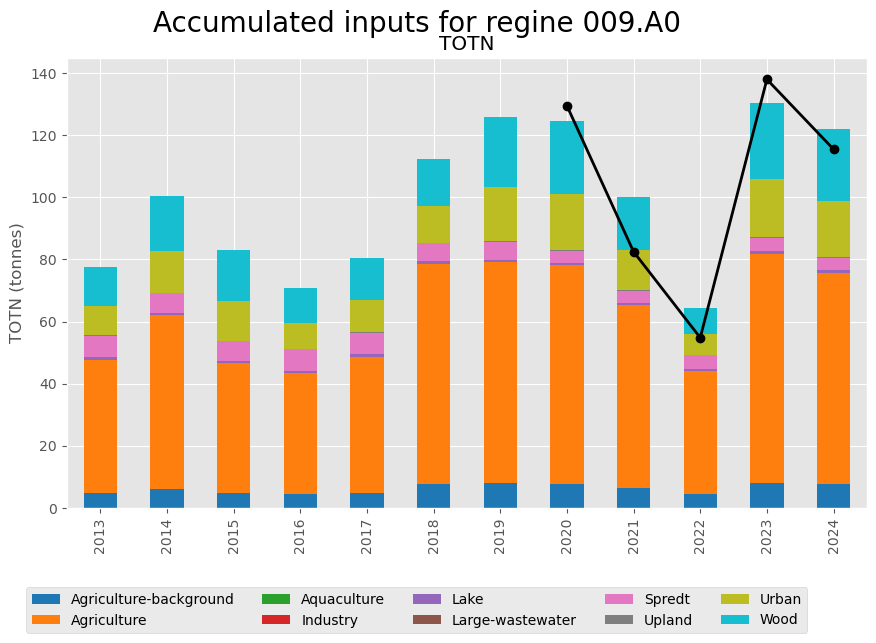

In [10]:
# Read model results
eval_fold = r"/home/jovyan/shared/common/teotil3/evaluation"
mod_csv = os.path.join(
    eval_fold,
    f"teo3_results_nve{nve_data_year}_{teo3_st_yr}-{teo3_end_yr}_agri-{agri_loss}-loss.csv",
)
mod_df = pd.read_csv(mod_csv)

# Plot results for Åroselva
axes = teo.vis.plot_regine_barchart(reg_id, mod_df, stat="accum", index_col="year")

# Add line with observed data
years = mod_df.query("regine == @reg_id")["year"]
obs = lds_df.set_index("year").reindex(years)["TOTN_tonn"]
axes[0].plot(
    range(len(obs)),
    obs,
    color="black",
    marker="o",
    linewidth=2,
    label="Observed TOTN",
)

# Just TOTN
ax0 = axes[0]
for a in axes[1:]:
    a.remove()
fig = ax0.figure
fig.set_size_inches(10, 6)
ax0.set_position([0.15, 0.15, 0.8, 0.75])

### 5.2. For the whole of vassdrgasområde 009

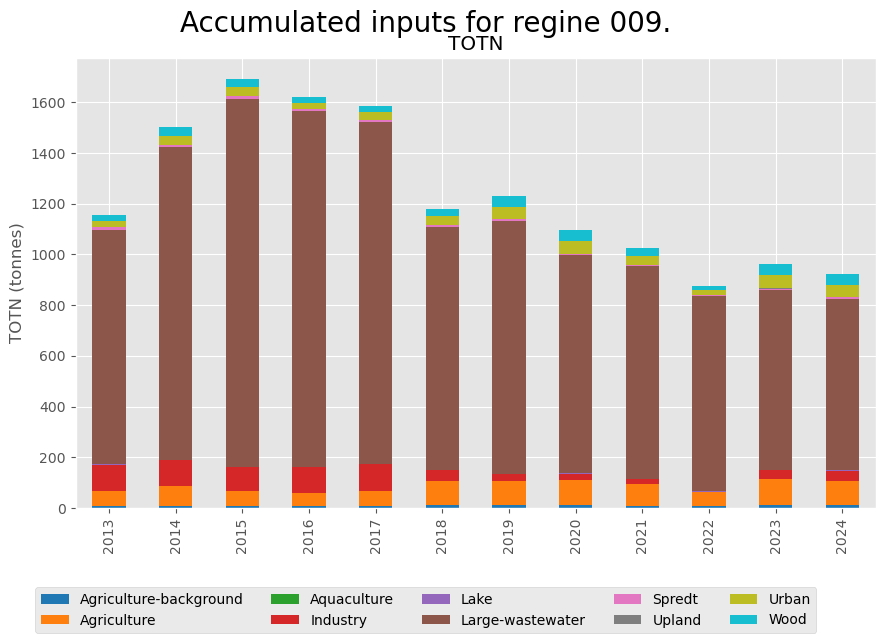

In [11]:
# Plot results for Åroselva
axes = teo.vis.plot_regine_barchart('009.', mod_df, stat="accum", index_col="year")

# Just TOTN
ax0 = axes[0]
for a in axes[1:]:
    a.remove()
fig = ax0.figure
fig.set_size_inches(10, 6)
ax0.set_position([0.15, 0.15, 0.8, 0.75])